# Notebook 19 — giải thích Cross-Attention 3 modalities

Notebook này **không huấn luyện lại**. Nó nạp 5 checkpoint Cross-Attention đã dùng trong notebook 17/18 (seed 5, 6, 7, 37, 42), sau đó chạy:

1. Integrated Gradients (IG) cho logit pathogenic, theo từng token DNA/protein và từng bio/geometry feature.
2. IG với baseline alt = ref để khảo sát ảnh hưởng của thay đổi allele trong chính model.
3. Occlusion: thay embedding alt tại từng offset bằng embedding ref; thay từng feature bằng median từ train.
4. Lưu attention map theo layer/head để quan sát luồng thông tin.

Mặc định giải thích một mẫu phân tầng theo nhãn trên mỗi tập test và mỗi seed có thể tốn thời gian. Điều chỉnh ngân sách trong cell cấu hình. Kết quả là giải thích của model trên embedding đã trích xuất; nó không trực tiếp chứng minh quan hệ nhân quả sinh học hay attribution đến nucleotide bên trong foundation model.

In [1]:
from pathlib import Path
from datetime import datetime
import importlib
import json
import os
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "core").is_dir() and (path / "controllers").is_dir()),
    Path.cwd(),
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Edit this if the dataset is mounted somewhere else on your computer.
BASE_DIR = Path("F:/variant_data")
SOURCE_BATCH_DIR = REPO_ROOT / "experiments" / "fm_ablation_20261117_003149"
REFERENCE_BATCH_DIR = REPO_ROOT / "experiments" / "fusion_classifier_benchmark_20261120_192605"
SOURCE_RUNS_ROOT = (
    SOURCE_BATCH_DIR / "module06_architecture_experiments"
    / "step2_sequence_length_ablation" / "runs"
)
TOKEN_CACHE_INDEX_PATH = (
    REFERENCE_BATCH_DIR / "module06_architecture_experiments"
    / "fm_ablation_token_cache_index.json"
)
OUTPUT_ROOT = REPO_ROOT / "experiments" / "cross_attention_explainability_v1"

DNA_MODEL_NAME = "nt_v1_500m_dna_1001"
PROTEIN_MODEL_NAME = "esm1b_650m_prot_501"
GEOMETRY_ROOT_NAME = "geometry_v2_k64_step2_matched"
GEOMETRY_ROOT = BASE_DIR / GEOMETRY_ROOT_NAME / "{context}"
FM_PROFILE_JSON = BASE_DIR / "profiling" / "fm_profiling_sequence_ablation.json"

SEEDS_TO_EXPLAIN = [5, 6, 7, 37, 42]
DATASETS_TO_EXPLAIN = {
    "test": "Train3Val_Test",
    "clinvarhq": "Train3Val_ClinVarHQ",
    "proteingym": "Train3Val_ProteinGym",
    "uniprot": "Train3Val_UniProt",
}
MAX_IG_SAMPLES_PER_DATASET = 8
BACKGROUND_SAMPLES = 64
IG_STEPS = 32
IG_INTERNAL_BATCH_SIZE = 8
RUN_FULL_PREDICTION_IG = True
RUN_ALT_VS_REF_IG = True
RUN_ATTENTION_MAPS = True
ATTENTION_SAMPLES_PER_DATASET = 1
RUN_OCCLUSION = True
OCCLUSION_SEEDS = [42]
OCCLUSION_SAMPLES_PER_DATASET = 2
OCCLUSION_CHUNK_SIZE = 16
RESUME_EXPLANATIONS = True

BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_CONFIG = {
    "attention_dropout": 0.18776012701077605,
    "dropout": 0.1955626033738947,
    "early_stop_patience": 6,
    "feature_dropout": 0.2507543060224074,
    "ffn_multiplier": 4,
    "k_radius": 16,
    "learning_rate": 0.00012206472463506827,
    "lr_factor": 0.5,
    "lr_patience": 3,
    "max_epochs": 30,
    "model_dim": 512,
    "num_heads": 8,
    "num_layers": 3,
    "pooling": "mean",
    "weight_decay": 3.380881049679085e-06,
}
print("Repo:", REPO_ROOT)
print("Device:", DEVICE)
print("Output:", OUTPUT_ROOT)

Repo: d:\Missense_variant_pathogenicity_prediction
Device: cuda
Output: d:\Missense_variant_pathogenicity_prediction\experiments\cross_attention_explainability_v1


In [2]:
from core.module05v2_fusion_classifier.pipeline import FusionBatchPipeline
from core.module05v2_fusion_classifier.dataset import BIO_CORE_COLUMNS, SPLICEAI_COLUMNS
from core.module06_architecture_experiments.fm_ablation_preparation import (
    build_model_configs, build_split_configs,
)
from core.module06_architecture_experiments.cross_attention_ablation_studies import GEOM_FEATURES
from core.module06_architecture_experiments.architecture_experiment_runner import (
    _architecture_loader, _attach_token_cache,
)
from core.module06_architecture_experiments.cross_attention_3modal_experiment import (
    _builder as build_cross_attention_model,
)
from core.module06_architecture_experiments.cross_attention_explainability import (
    empirical_baseline, alt_equals_ref_baseline, integrated_gradients,
    select_stratified_indices, attention_summary_rows, occlusion_logit_deltas,
    move_batch_to_device, upsert_csv,
)

if not TOKEN_CACHE_INDEX_PATH.is_file():
    raise FileNotFoundError(f"Notebook 17 token cache index is missing: {TOKEN_CACHE_INDEX_PATH}")
TOKEN_CACHE_INDEX = json.loads(TOKEN_CACHE_INDEX_PATH.read_text(encoding="utf-8"))

DNA_MODEL, PROTEIN_MODEL = [
    next(model for model in build_model_configs(1001, 501) if model["name"] == name)
    for name in (DNA_MODEL_NAME, PROTEIN_MODEL_NAME)
]
SPLITS = build_split_configs(BASE_DIR)
DATASETS = [
    {"name": "Train3Val_Test", "train": "train3", "val": "val", "test": "test"},
    {"name": "Train3Val_ClinVarHQ", "train": "train3", "val": "val", "test": "clinvarhq"},
    {"name": "Train3Val_ProteinGym", "train": "train3", "val": "val", "test": "proteingym"},
    {"name": "Train3Val_UniProt", "train": "train3", "val": "val", "test": "uniprot"},
]
BIO_FEATURE_NAMES = [*BIO_CORE_COLUMNS, *SPLICEAI_COLUMNS]
TARGET = {
    "name": "B_with_geometry",
    "ablation": "bio_core_dna_prot_spliceai_geom",
    "active_modalities": ["dna", "prot", "bio_core", "spliceai", "geom"],
    "bio_feature_names": BIO_FEATURE_NAMES,
    "geom_feature_names": list(GEOM_FEATURES),
    "geometry_dna_name": DNA_MODEL_NAME,
    "geometry_protein_name": PROTEIN_MODEL_NAME,
}
PIPELINE_CONFIG = {
    "batch_size": BATCH_SIZE,
    "epochs": MODEL_CONFIG["max_epochs"],
    "lr": MODEL_CONFIG["learning_rate"],
    "weight_decay": MODEL_CONFIG["weight_decay"],
    "lr_factor": MODEL_CONFIG["lr_factor"],
    "lr_patience": MODEL_CONFIG["lr_patience"],
    "early_stop_patience": MODEL_CONFIG["early_stop_patience"],
    "num_workers": 0,
    "seed": SEEDS_TO_EXPLAIN[0],
    "xgb_n_jobs": 1,
}
pipeline = FusionBatchPipeline(
    base_dir=str(BASE_DIR),
    config=PIPELINE_CONFIG,
    datasets=DATASETS,
    models_space=[DNA_MODEL, PROTEIN_MODEL],
    pooling_strategies=["center"],
    experiments=[{"name": "CrossAttentionExplainability", "type": "pytorch", "fusion": "cross_attention"}],
    explainability={"enable_shap": False, "enable_lime": False},
    fm_profile_json=str(FM_PROFILE_JSON),
    geom_profile_json=None,
    geometry_dir=str(GEOMETRY_ROOT),
    geom_feature_names=GEOM_FEATURES,
    batch_run_dir=str(OUTPUT_ROOT),
    embedding_dir=str(BASE_DIR / "fm_embeddings" / "sequence_ablation"),
)
CONTEXT = {
    "pipeline": pipeline,
    "TARGET_CONFIGS": [TARGET],
    "datasets": DATASETS,
    "DNA_MODEL": DNA_MODEL,
    "PROTEIN_MODEL": PROTEIN_MODEL,
    "DEVICE": DEVICE,
    "token_embedding_cache_index": TOKEN_CACHE_INDEX,
    "token_batch_size": BATCH_SIZE,
    "token_only": True,
}
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("DNA/Protein:", DNA_MODEL_NAME, "+", PROTEIN_MODEL_NAME)
print("Geometry:", GEOMETRY_ROOT_NAME, "| k=64 | features:", len(GEOM_FEATURES))
print("Bio + SpliceAI features:", len(BIO_FEATURE_NAMES))
print("Selected seeds:", SEEDS_TO_EXPLAIN)
print("Explanation splits:", DATASETS_TO_EXPLAIN)

c:\Users\Dung\anaconda3\envs\missense_variant_patho_predict_clean\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DNA/Protein: nt_v1_500m_dna_1001 + esm1b_650m_prot_501
Geometry: geometry_v2_k64_step2_matched | k=64 | features: 8
Bio + SpliceAI features: 20
Selected seeds: [5, 6, 7, 37, 42]
Explanation splits: {'test': 'Train3Val_Test', 'clinvarhq': 'Train3Val_ClinVarHQ', 'proteingym': 'Train3Val_ProteinGym', 'uniprot': 'Train3Val_UniProt'}


In [3]:
SOURCE_INFO = {}
audit_rows = []
EXPECTED_ARCHITECTURE = "cross_attention_3modal_ref_alt_concat_window33_sequence_length_ablation"
EXPECTED_VARIANT = "ref_alt_concat_window_33_sequence_length_ablation"

for seed in SEEDS_TO_EXPLAIN:
    run_name = f"step2_nt_v1_dna1001_esm1b_prot501_seed{seed}"
    run_dir = SOURCE_RUNS_ROOT / run_name
    checkpoint = run_dir / "checkpoints" / "B_with_geometry" / "best_model.pth"
    manifest_path = run_dir / "_resume_manifest.json"
    validation_paths = list(run_dir.glob("*_validation_metrics.csv"))
    if not checkpoint.is_file() or not manifest_path.is_file() or not validation_paths:
        raise FileNotFoundError(f"Incomplete source checkpoint bundle for seed {seed}: {run_dir}")

    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    saved = manifest.get("config", {})
    mismatches = []
    if saved.get("architecture") != EXPECTED_ARCHITECTURE:
        mismatches.append("architecture")
    if saved.get("variant") != EXPECTED_VARIANT:
        mismatches.append("variant")
    if saved.get("dna_model", {}).get("name") != DNA_MODEL_NAME:
        mismatches.append("DNA model")
    if saved.get("protein_model", {}).get("name") != PROTEIN_MODEL_NAME:
        mismatches.append("protein model")
    signature = saved.get("input_data_signature", {})
    if signature.get("geometry_root") != GEOMETRY_ROOT_NAME:
        mismatches.append("geometry root")
    if signature.get("token_window") != "variant-centered ref/alt, k_radius=16, length=33":
        mismatches.append("token window")
    config_keys = [key for key in saved if key.startswith(run_name + "_config")]
    if len(config_keys) != 1:
        mismatches.append("seed-specific model config")
    else:
        source_model_config = saved[config_keys[0]]
        model_keys = ("attention_dropout", "dropout", "feature_dropout",
                      "ffn_multiplier", "k_radius", "model_dim",
                      "num_heads", "num_layers", "pooling")
        if any(source_model_config.get(key) != MODEL_CONFIG[key] for key in model_keys):
            mismatches.append("model hyperparameters")
    saved_target = saved.get("target_configs", [{}])[0]
    if saved_target.get("name") != "B_with_geometry":
        mismatches.append("target config")
    if saved_target.get("geom_feature_names") != list(GEOM_FEATURES):
        mismatches.append("geometry feature set")

    validation = pd.read_csv(validation_paths[0])
    selected = validation[
        validation["Target_Config"].astype(str).eq("B_with_geometry")
        & pd.to_numeric(validation["Seed"], errors="coerce").eq(int(seed))
    ]
    if selected.empty:
        raise ValueError(f"No validation record for seed {seed} in {validation_paths[0]}")
    row = selected.iloc[0]
    if mismatches:
        raise ValueError(f"Seed {seed} checkpoint does not match this notebook: {mismatches}")
    SOURCE_INFO[int(seed)] = {
        "checkpoint": str(checkpoint.resolve()),
        "validation_csv": str(validation_paths[0].resolve()),
        "best_epoch": int(float(row.get("Best_Epoch", 1))),
        "val_mcc": float(row["Val_MCC"]),
        "threshold": float(row["Decision_Threshold"]),
    }
    audit_rows.append({
        "Seed": int(seed),
        "Best_Epoch": SOURCE_INFO[int(seed)]["best_epoch"],
        "Val_MCC": SOURCE_INFO[int(seed)]["val_mcc"],
        "Threshold": SOURCE_INFO[int(seed)]["threshold"],
        "Checkpoint": str(checkpoint),
        "Status": "ready",
    })

CHECKPOINT_AUDIT = pd.DataFrame(audit_rows)
display(CHECKPOINT_AUDIT)

,Seed,Best_Epoch,Val_MCC,Threshold,Checkpoint,Status
0,5,2,0.8209,0.888212,d:\Missense_variant_pathogenicity_prediction\e...,ready
1,6,4,0.8238,0.918221,d:\Missense_variant_pathogenicity_prediction\e...,ready
2,7,2,0.8235,0.559536,d:\Missense_variant_pathogenicity_prediction\e...,ready
3,37,2,0.8243,0.479132,d:\Missense_variant_pathogenicity_prediction\e...,ready
4,42,2,0.8210,0.814246,d:\Missense_variant_pathogenicity_prediction\e...,ready


In [4]:
def make_explanation_loader(split_name, seed):
    base_loader = _architecture_loader(
        pipeline=pipeline,
        context=CONTEXT,
        target=TARGET,
        split_name=split_name,
        pooling="center",
        dna_model=DNA_MODEL,
        protein_model=PROTEIN_MODEL,
        is_train=False,
        geometry_context="train3",
        seed=int(seed),
        embedding_representation="ref_alt_concat",
    )
    return _attach_token_cache(
        base_loader,
        CONTEXT,
        split_name,
        is_train=False,
        window_radius=int(MODEL_CONFIG["k_radius"]),
    )


def load_seed_model(seed, dataset):
    dimensions = {
        "token_dna": int(dataset.token_hidden_sizes["dna"]),
        "token_protein": int(dataset.token_hidden_sizes["protein"]),
        "bio": int(dataset.bio_tensor.shape[1]),
        "geometry": int(dataset.geom_tensor.shape[1]),
    }
    model = build_cross_attention_model(dimensions, MODEL_CONFIG).to(DEVICE)
    state = torch.load(SOURCE_INFO[int(seed)]["checkpoint"], map_location=DEVICE, weights_only=True)
    model.load_state_dict(state)
    model.eval()
    return model


def _sample_value(batch, key, default=None):
    value = batch.get(key, default)
    if isinstance(value, (list, tuple, np.ndarray)):
        return value[0]
    if torch.is_tensor(value) and value.numel() == 1:
        return value.reshape(-1)[0].item()
    return value


def _safe_filename(value):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value)).strip("_") or "sample"


def _base_record(seed, dataset_name, variant_id, true_label):
    source = SOURCE_INFO[int(seed)]
    return {
        "Seed": int(seed),
        "Dataset": str(dataset_name),
        "Variant_ID": str(variant_id),
        "True_Label": int(true_label),
        "Checkpoint": source["checkpoint"],
        "Best_Epoch": source["best_epoch"],
        "Val_MCC": source["val_mcc"],
        "Decision_Threshold": source["threshold"],
    }


print("Loader and checkpoint functions ready.")

Loader and checkpoint functions ready.


## Empirical baseline

Full-prediction IG uses mean token embeddings and median tabular values computed from a reproducible, class-stratified sample of the **train** split. A second IG baseline copies each ref token embedding into the corresponding alt position while retaining observed bio/geometry values. The second mode isolates allele-state differences under this model; it is not a causal intervention.

In [5]:
TRAIN_LOADER = make_explanation_loader("train3", SEEDS_TO_EXPLAIN[0])
background_indices = select_stratified_indices(
    TRAIN_LOADER.dataset, BACKGROUND_SAMPLES, seed=2026
)
BACKGROUND_BATCH = TRAIN_LOADER.dataset[background_indices]
FULL_IG_BASELINE = empirical_baseline(BACKGROUND_BATCH, BACKGROUND_BATCH)
print(
    f"Empirical baseline built from {len(background_indices)} train variants; "
    f"DNA window={tuple(FULL_IG_BASELINE['token_dna'].shape)}, "
    f"protein window={tuple(FULL_IG_BASELINE['token_protein'].shape)}"
)
del BACKGROUND_BATCH, TRAIN_LOADER

[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['bio_core', 'spliceai', 'geom']
[+] Dataset sẵn sàng: 23208 mẫu. Đã tối ưu hóa RAM & CPU 100%.



Window cache dna/train3: 100%|██████████| 11604/11604 [00:06<00:00, 1868.71shard/s]


[Window cache] dna/train3: 23208 samples ready in 6.2s


Window cache protein/train3: 100%|██████████| 1451/1451 [00:01<00:00, 997.61shard/s] 


[Window cache] protein/train3: 23208 samples ready in 1.5s
Empirical baseline built from 64 train variants; DNA window=(1, 2, 33, 1280), protein window=(1, 2, 33, 1280)


## Run explanations

Per-sample tables are written after each sample so an interrupted run can be resumed. If you change the seeds, datasets, baseline sample count, IG steps, or other run settings, change `OUTPUT_ROOT` to a new folder.

In [6]:
RUN_SIGNATURE = {
    "source_batch": str(SOURCE_BATCH_DIR.resolve()),
    "source_checkpoints": {str(seed): SOURCE_INFO[seed]["checkpoint"] for seed in SEEDS_TO_EXPLAIN},
    "seeds": list(map(int, SEEDS_TO_EXPLAIN)),
    "datasets": DATASETS_TO_EXPLAIN,
    "model_config": MODEL_CONFIG,
    "max_ig_samples_per_dataset": int(MAX_IG_SAMPLES_PER_DATASET),
    "background_samples": int(BACKGROUND_SAMPLES),
    "ig_steps": int(IG_STEPS),
    "ig_internal_batch_size": int(IG_INTERNAL_BATCH_SIZE),
    "run_full_prediction_ig": bool(RUN_FULL_PREDICTION_IG),
    "run_alt_vs_ref_ig": bool(RUN_ALT_VS_REF_IG),
    "run_attention_maps": bool(RUN_ATTENTION_MAPS),
    "attention_samples_per_dataset": int(ATTENTION_SAMPLES_PER_DATASET),
    "run_occlusion": bool(RUN_OCCLUSION),
    "occlusion_seeds": list(map(int, OCCLUSION_SEEDS)),
    "occlusion_samples_per_dataset": int(OCCLUSION_SAMPLES_PER_DATASET),
    "occlusion_chunk_size": int(OCCLUSION_CHUNK_SIZE),
}
signature_path = OUTPUT_ROOT / "run_signature.json"
if signature_path.is_file():
    previous_signature = json.loads(signature_path.read_text(encoding="utf-8"))
    if previous_signature != RUN_SIGNATURE:
        raise ValueError(
            "Explanation settings differ from the existing output. "
            "Change OUTPUT_ROOT to a new experiment folder before running."
        )
else:
    signature_path.write_text(json.dumps(RUN_SIGNATURE, indent=2), encoding="utf-8")

csv_paths = {
    "predictions": OUTPUT_ROOT / "ig_predictions.csv",
    "completeness": OUTPUT_ROOT / "ig_completeness.csv",
    "modalities": OUTPUT_ROOT / "ig_modality_attributions.csv",
    "positions": OUTPUT_ROOT / "ig_token_positions.csv",
    "features": OUTPUT_ROOT / "ig_tabular_features.csv",
    "attention": OUTPUT_ROOT / "attention_summary.csv",
    "occlusion": OUTPUT_ROOT / "occlusion_logit_deltas.csv",
}
done_completeness = set()
if RESUME_EXPLANATIONS and csv_paths["completeness"].is_file():
    completed = pd.read_csv(csv_paths["completeness"])
    done_completeness = {
        (int(row.Seed), str(row.Dataset), str(row.Variant_ID), str(row.Attribution_Mode))
        for row in completed.itertuples()
    }

feature_names_by_key = {
    "bio_features": BIO_FEATURE_NAMES,
    "geom_features": list(GEOM_FEATURES),
}
attribute_modes = []
if RUN_FULL_PREDICTION_IG:
    attribute_modes.append(("full_prediction", FULL_IG_BASELINE))
if RUN_ALT_VS_REF_IG:
    attribute_modes.append(("alt_vs_ref", None))

for split_name, dataset_name in DATASETS_TO_EXPLAIN.items():
    print(f"\n[DATA] Preparing {dataset_name} ({split_name})")
    loader = make_explanation_loader(split_name, SEEDS_TO_EXPLAIN[0])
    sample_indices = select_stratified_indices(
        loader.dataset, MAX_IG_SAMPLES_PER_DATASET, seed=2026
    )
    split_attention_counts = {seed: 0 for seed in SEEDS_TO_EXPLAIN}
    split_occlusion_counts = {seed: 0 for seed in OCCLUSION_SEEDS}

    for seed in SEEDS_TO_EXPLAIN:
        model = load_seed_model(seed, loader.dataset)
        for sample_number, index in enumerate(sample_indices):
            one = loader.dataset[int(index)]
            variant_id = str(_sample_value(one, "variant_id"))
            true_label = int(float(_sample_value(one, "label")))
            base = _base_record(seed, dataset_name, variant_id, true_label)

            if (RUN_FULL_PREDICTION_IG or RUN_ALT_VS_REF_IG):
                prediction_row_written = False
                for mode, configured_baseline in attribute_modes:
                    identity = (int(seed), str(dataset_name), variant_id, mode)
                    if RESUME_EXPLANATIONS and identity in done_completeness:
                        continue
                    baseline = (
                        configured_baseline
                        if configured_baseline is not None
                        else alt_equals_ref_baseline(one)
                    )
                    result = integrated_gradients(
                        model,
                        one,
                        baseline,
                        device=DEVICE,
                        n_steps=IG_STEPS,
                        internal_batch_size=IG_INTERNAL_BATCH_SIZE,
                    )
                    probability = float(torch.sigmoid(torch.tensor(result["actual_logit"])).item())
                    threshold = SOURCE_INFO[int(seed)]["threshold"]
                    predicted = int(probability >= threshold)
                    if not prediction_row_written:
                        upsert_csv(csv_paths["predictions"], [{
                            **base,
                            "Probability_Pathogenic": probability,
                            "Predicted_Label": predicted,
                        }], ["Seed", "Dataset", "Variant_ID"])
                        prediction_row_written = True

                    completeness_row = {
                        **base,
                        "Attribution_Mode": mode,
                        "Actual_Pathogenic_Logit": result["actual_logit"],
                        "Baseline_Pathogenic_Logit": result["baseline_logit"],
                        "IG_Completeness_Residual": result["completeness_residual"],
                        "IG_Steps": int(IG_STEPS),
                    }
                    modality_rows, position_rows, feature_rows = [], [], []
                    for key, attribution in result["attributions"].items():
                        modality = {
                            "token_dna": "DNA",
                            "token_protein": "Protein",
                            "bio_features": "Bio_SpliceAI",
                            "geom_features": "Geometry",
                        }[key]
                        modality_rows.append({
                            **base,
                            "Attribution_Mode": mode,
                            "Modality": modality,
                            "Signed_Attribution_Sum": float(attribution.sum().item()),
                            "Absolute_Attribution_Sum": float(attribution.abs().sum().item()),
                        })
                        if key in ("token_dna", "token_protein"):
                            values = attribution[0].numpy()  # [ref/alt, relative token, hidden dim]
                            for allele_index, allele in enumerate(("Ref", "Alt")):
                                for position in range(values.shape[1]):
                                    signed = float(values[allele_index, position].sum())
                                    magnitude = float(np.abs(values[allele_index, position]).sum())
                                    position_rows.append({
                                        **base,
                                        "Attribution_Mode": mode,
                                        "Modality": modality,
                                        "Allele": allele,
                                        "Relative_Token_Position": position - int(MODEL_CONFIG["k_radius"]),
                                        "Signed_Attribution": signed,
                                        "Absolute_Attribution": magnitude,
                                    })
                        else:
                            names = feature_names_by_key[key]
                            values = attribution[0].numpy().reshape(-1)
                            for feature_index, feature_name in enumerate(names):
                                feature_rows.append({
                                    **base,
                                    "Attribution_Mode": mode,
                                    "Feature": str(feature_name),
                                    "Input_Value": float(one[key].reshape(-1)[feature_index].item()),
                                    "Signed_Attribution": float(values[feature_index]),
                                    "Absolute_Attribution": float(abs(values[feature_index])),
                                })

                    upsert_csv(
                        csv_paths["modalities"], modality_rows,
                        ["Seed", "Dataset", "Variant_ID", "Attribution_Mode", "Modality"],
                    )
                    upsert_csv(
                        csv_paths["positions"], position_rows,
                        ["Seed", "Dataset", "Variant_ID", "Attribution_Mode",
                         "Modality", "Allele", "Relative_Token_Position"],
                    )
                    upsert_csv(
                        csv_paths["features"], feature_rows,
                        ["Seed", "Dataset", "Variant_ID", "Attribution_Mode", "Feature"],
                    )
                    upsert_csv(
                        csv_paths["completeness"], [completeness_row],
                        ["Seed", "Dataset", "Variant_ID", "Attribution_Mode"],
                    )
                    done_completeness.add(identity)
                    print(
                        f"[IG] seed={seed} {dataset_name} {variant_id} {mode} "
                        f"logit={result['actual_logit']:.4f} residual={result['completeness_residual']:.3g}"
                    )

            if RUN_ATTENTION_MAPS and split_attention_counts[seed] < ATTENTION_SAMPLES_PER_DATASET:
                attention_dir = OUTPUT_ROOT / "attention_maps" / dataset_name / f"seed_{seed}"
                attention_dir.mkdir(parents=True, exist_ok=True)
                attention_path = attention_dir / f"{_safe_filename(variant_id)}.npz"
                if not (RESUME_EXPLANATIONS and attention_path.is_file()):
                    batch = move_batch_to_device(one, DEVICE)
                    values = {
                        key: batch[key].to(torch.float32)
                        for key in ("token_dna", "token_protein", "bio_features", "geom_features")
                        if batch.get(key) is not None
                    }
                    with torch.no_grad():
                        _, attention_maps = model(
                            batch["v_dna"], batch["v_prot"], values["bio_features"],
                            values.get("geom_features"),
                            token_dna=values["token_dna"],
                            token_dna_mask=batch["token_dna_mask"],
                            token_dna_variant_index=batch["token_dna_variant_index"],
                            token_protein=values["token_protein"],
                            token_protein_mask=batch["token_protein_mask"],
                            token_protein_variant_index=batch["token_protein_variant_index"],
                            return_attention=True,
                        )
                    np.savez_compressed(
                        attention_path,
                        **{name: tensor.detach().cpu().numpy() for name, tensor in attention_maps.items()},
                    )
                    rows = attention_summary_rows(
                        attention_maps,
                        seed=seed,
                        dataset=dataset_name,
                        variant_id=variant_id,
                        token_radius=MODEL_CONFIG["k_radius"],
                        bio_feature_names=BIO_FEATURE_NAMES,
                        geom_feature_names=GEOM_FEATURES,
                    )
                    for row in rows:
                        row["True_Label"] = true_label
                    upsert_csv(
                        csv_paths["attention"], rows,
                        ["Seed", "Dataset", "Variant_ID", "Layer", "Query_Modality",
                         "Context_Modality", "Context_Token"],
                    )
                    print(f"[ATTENTION] Saved {attention_path}")
                split_attention_counts[seed] += 1

            if (
                RUN_OCCLUSION and seed in OCCLUSION_SEEDS
                and split_occlusion_counts[seed] < OCCLUSION_SAMPLES_PER_DATASET
            ):
                already_occluded = False
                if RESUME_EXPLANATIONS and csv_paths["occlusion"].is_file():
                    previous = pd.read_csv(csv_paths["occlusion"], usecols=["Seed", "Dataset", "Variant_ID"])
                    already_occluded = bool(
                        ((previous["Seed"] == int(seed))
                         & (previous["Dataset"].astype(str) == str(dataset_name))
                         & (previous["Variant_ID"].astype(str) == variant_id)).any()
                    )
                if not already_occluded:
                    occlusion_rows = occlusion_logit_deltas(
                        model,
                        one,
                        device=DEVICE,
                        token_radius=MODEL_CONFIG["k_radius"],
                        bio_feature_names=BIO_FEATURE_NAMES,
                        geom_feature_names=GEOM_FEATURES,
                        feature_baseline=FULL_IG_BASELINE,
                        chunk_size=OCCLUSION_CHUNK_SIZE,
                    )
                    for row in occlusion_rows:
                        row.update(base)
                    upsert_csv(
                        csv_paths["occlusion"], occlusion_rows,
                        ["Seed", "Dataset", "Variant_ID", "Feature_or_Position"],
                    )
                    print(f"[OCCLUSION] seed={seed} {dataset_name} {variant_id}: {len(occlusion_rows)} perturbations")
                split_occlusion_counts[seed] += 1

        del model
    del loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Explanation computation complete:", OUTPUT_ROOT)


[DATA] Preparing Train3Val_Test (test)
[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['bio_core', 'spliceai', 'geom']
[+] Dataset sẵn sàng: 6095 mẫu. Đã tối ưu hóa RAM & CPU 100%.



Window cache dna/test: 100%|██████████| 3048/3048 [00:01<00:00, 1911.14shard/s]


[Window cache] dna/test: 6095 samples ready in 1.6s


Window cache protein/test: 100%|██████████| 381/381 [00:00<00:00, 1022.80shard/s]


[Window cache] protein/test: 6095 samples ready in 0.4s

[DATA] Preparing Train3Val_ClinVarHQ (clinvarhq)
[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['bio_core', 'spliceai', 'geom']
[+] Dataset sẵn sàng: 703 mẫu. Đã tối ưu hóa RAM & CPU 100%.



Window cache dna/clinvarhq: 100%|██████████| 352/352 [00:00<00:00, 1941.03shard/s]


... (7 outputs left out)

Window cache dna/uniprot: 100%|██████████| 667/667 [00:00<00:00, 1883.46shard/s]


[Window cache] dna/uniprot: 1333 samples ready in 0.4s


Window cache protein/uniprot: 100%|██████████| 84/84 [00:00<00:00, 1038.86shard/s]


[Window cache] protein/uniprot: 1333 samples ready in 0.1s
[IG] seed=7 Train3Val_UniProt 15_26621403_T_G alt_vs_ref logit=4.6469 residual=-1.4e-05
[IG] seed=7 Train3Val_UniProt 15_89320890_G_A full_prediction logit=4.3404 residual=0.000452
[IG] seed=7 Train3Val_UniProt 15_89320890_G_A alt_vs_ref logit=4.3404 residual=-1.91e-06
[IG] seed=7 Train3Val_UniProt 15_90441622_T_C full_prediction logit=-2.6339 residual=-0.00139
[IG] seed=7 Train3Val_UniProt 15_90441622_T_C alt_vs_ref logit=-2.6339 residual=9.74e-06
[IG] seed=7 Train3Val_UniProt 20_32310525_G_C full_prediction logit=5.4741 residual=0.00926
[IG] seed=7 Train3Val_UniProt 20_32310525_G_C alt_vs_ref logit=5.4741 residual=-8.27e-07
[IG] seed=7 Train3Val_UniProt 20_38156053_C_G full_prediction logit=-0.5629 residual=-0.00199
[IG] seed=7 Train3Val_UniProt 20_38156053_C_G alt_vs_ref logit=-0.5629 residual=-5.17e-06
[IG] seed=37 Train3Val_UniProt 10_5960405_T_C full_prediction logit=-2.0142 residual=0.00216
[IG] seed=37 Train3Val_UniProt

## Tổng hợp và hiển thị

IG có dấu cho biết hướng đóng góp vào logit; trị tuyệt đối cho biết độ lớn. Các bảng được tổng hợp theo từng tập, seed, nhãn và feature/token. Attention chỉ được hiển thị như phân bố trọng số truy cập context; kiểm tra nó cùng IG/occlusion, không diễn giải nó như tác động nhân quả.

In [7]:
def _read_result(name):
    path = csv_paths[name]
    return pd.read_csv(path) if path.is_file() else pd.DataFrame()

IG_MODALITIES = _read_result("modalities")
IG_POSITIONS = _read_result("positions")
IG_FEATURES = _read_result("features")
ATTENTION_SUMMARY = _read_result("attention")
OCCLUSION = _read_result("occlusion")
IG_COMPLETENESS = _read_result("completeness")
IG_PREDICTIONS = _read_result("predictions")

if not IG_POSITIONS.empty:
    position_summary = (
        IG_POSITIONS.groupby(
            ["Dataset", "Attribution_Mode", "Modality", "Allele",
             "Relative_Token_Position", "True_Label"], dropna=False
        )
        .agg(
            Mean_Signed_Attribution=("Signed_Attribution", "mean"),
            Mean_Absolute_Attribution=("Absolute_Attribution", "mean"),
            SD_Absolute_Attribution=("Absolute_Attribution", "std"),
            N=("Absolute_Attribution", "size"),
        )
        .reset_index()
    )
    position_summary.to_csv(OUTPUT_ROOT / "ig_token_position_summary.csv", index=False)
    display(position_summary.head(30))
    position_by_seed = (
        IG_POSITIONS.groupby(
            ["Dataset", "Attribution_Mode", "Modality", "Allele",
             "Relative_Token_Position", "True_Label", "Seed"], dropna=False
        )["Absolute_Attribution"].mean().rename("Seed_Mean_Absolute_Attribution").reset_index()
    )
    position_seed_stability = (
        position_by_seed.groupby(
            ["Dataset", "Attribution_Mode", "Modality", "Allele",
             "Relative_Token_Position", "True_Label"], dropna=False
        )["Seed_Mean_Absolute_Attribution"].agg(["mean", "std", "count"]).reset_index()
        .rename(columns={"mean": "Mean_Of_Seed_Means", "std": "SD_Across_Seeds", "count": "N_Seeds"})
    )
    position_seed_stability.to_csv(OUTPUT_ROOT / "ig_token_position_seed_stability.csv", index=False)

if not IG_FEATURES.empty:
    feature_summary = (
        IG_FEATURES.groupby(
            ["Dataset", "Attribution_Mode", "Feature", "True_Label"], dropna=False
        )
        .agg(
            Mean_Signed_Attribution=("Signed_Attribution", "mean"),
            Mean_Absolute_Attribution=("Absolute_Attribution", "mean"),
            SD_Absolute_Attribution=("Absolute_Attribution", "std"),
            N=("Absolute_Attribution", "size"),
        )
        .reset_index()
        .sort_values(
            ["Dataset", "Attribution_Mode", "True_Label", "Mean_Absolute_Attribution"],
            ascending=[True, True, True, False],
        )
    )
    feature_summary.to_csv(OUTPUT_ROOT / "ig_feature_summary.csv", index=False)
    display(feature_summary.groupby(
        ["Dataset", "Attribution_Mode", "True_Label"], sort=False
    ).head(10))
    feature_by_seed = (
        IG_FEATURES.groupby(
            ["Dataset", "Attribution_Mode", "Feature", "True_Label", "Seed"], dropna=False
        )["Absolute_Attribution"].mean().rename("Seed_Mean_Absolute_Attribution").reset_index()
    )
    feature_seed_stability = (
        feature_by_seed.groupby(
            ["Dataset", "Attribution_Mode", "Feature", "True_Label"], dropna=False
        )["Seed_Mean_Absolute_Attribution"].agg(["mean", "std", "count"]).reset_index()
        .rename(columns={"mean": "Mean_Of_Seed_Means", "std": "SD_Across_Seeds", "count": "N_Seeds"})
    )
    feature_seed_stability.to_csv(OUTPUT_ROOT / "ig_feature_seed_stability.csv", index=False)

if not IG_MODALITIES.empty:
    modality_summary = (
        IG_MODALITIES.groupby(
            ["Dataset", "Attribution_Mode", "Modality", "True_Label"], dropna=False
        )
        .agg(
            Mean_Signed_Attribution=("Signed_Attribution_Sum", "mean"),
            Mean_Absolute_Attribution=("Absolute_Attribution_Sum", "mean"),
            SD_Absolute_Attribution=("Absolute_Attribution_Sum", "std"),
            N=("Absolute_Attribution_Sum", "size"),
        )
        .reset_index()
    )
    modality_summary.to_csv(OUTPUT_ROOT / "ig_modality_summary.csv", index=False)
    display(modality_summary)
    modality_by_seed = (
        IG_MODALITIES.groupby(
            ["Dataset", "Attribution_Mode", "Modality", "True_Label", "Seed"], dropna=False
        )["Absolute_Attribution_Sum"].mean().rename("Seed_Mean_Absolute_Attribution").reset_index()
    )
    modality_seed_stability = (
        modality_by_seed.groupby(
            ["Dataset", "Attribution_Mode", "Modality", "True_Label"], dropna=False
        )["Seed_Mean_Absolute_Attribution"].agg(["mean", "std", "count"]).reset_index()
        .rename(columns={"mean": "Mean_Of_Seed_Means", "std": "SD_Across_Seeds", "count": "N_Seeds"})
    )
    modality_seed_stability.to_csv(OUTPUT_ROOT / "ig_modality_seed_stability.csv", index=False)

if not OCCLUSION.empty:
    occlusion_summary = (
        OCCLUSION.groupby(
            ["Dataset", "Feature_or_Position", "True_Label"], dropna=False
        )
        .agg(
            Mean_Logit_Delta=("Logit_Delta_Actual_Minus_Occluded", "mean"),
            SD_Logit_Delta=("Logit_Delta_Actual_Minus_Occluded", "std"),
            Mean_Absolute_Logit_Delta=("Logit_Delta_Actual_Minus_Occluded",
                                       lambda values: values.abs().mean()),
            N=("Logit_Delta_Actual_Minus_Occluded", "size"),
        )
        .reset_index()
        .sort_values(
            ["Dataset", "True_Label", "Mean_Absolute_Logit_Delta"],
            ascending=[True, True, False],
        )
    )
    occlusion_summary.to_csv(OUTPUT_ROOT / "occlusion_summary.csv", index=False)
    display(occlusion_summary.groupby(["Dataset", "True_Label"], sort=False).head(15))

display(IG_COMPLETENESS.head(20))
display(IG_PREDICTIONS.head(20))

,Dataset,Attribution_Mode,Modality,Allele,Relative_Token_Position,True_Label,Mean_Signed_Attribution,Mean_Absolute_Attribution,SD_Absolute_Attribution,N
0,Train3Val_ClinVarHQ,alt_vs_ref,DNA,Alt,-16,0,2.955315e-05,0.001131,0.000475,20
1,Train3Val_ClinVarHQ,alt_vs_ref,DNA,Alt,-16,1,1.054055e-06,0.000893,0.000710,20
2,Train3Val_ClinVarHQ,alt_vs_ref,DNA,Alt,-15,0,7.656032e-05,0.001142,0.000426,20
3,Train3Val_ClinVarHQ,alt_vs_ref,DNA,Alt,-15,1,3.045738e-05,0.000954,0.000777,20
4,Train3Val_ClinVarHQ,alt_vs_ref,DNA,Alt,-14,0,5.861870e-05,0.001255,0.000382,20
5,Train3Val_ClinVarHQ,alt_vs_ref,DNA,Alt,-14,1,9.941414e-06,0.001346,0.001344,20
6,Train3Val_ClinVarHQ,alt_vs_ref,DNA,Alt,-13,0,7.011208e-05,0.001337,0.000463,20
7,Train3Val_ClinVarHQ,alt_vs_ref,DNA,Alt,-13,1,1.966328e-05,0.001001,0.000651,20
8,Train3Val_ClinVarHQ,alt_vs_ref,DNA,Alt,-12,0,5.620147e-05,0.001260,0.000432,20
9,Train3Val_ClinVarHQ,alt_vs_ref,DNA,Alt,-12,1,2.513358e-06,0.001043,0.000650,20


,Dataset,Attribution_Mode,Feature,True_Label,Mean_Signed_Attribution,Mean_Absolute_Attribution,SD_Absolute_Attribution,N
0,Train3Val_ClinVarHQ,alt_vs_ref,AF,0,0.000000,0.000000,0.000000,20
2,Train3Val_ClinVarHQ,alt_vs_ref,GERP++_NR,0,0.000000,0.000000,0.000000,20
4,Train3Val_ClinVarHQ,alt_vs_ref,GERP++_RS,0,0.000000,0.000000,0.000000,20
6,Train3Val_ClinVarHQ,alt_vs_ref,GERP_92_mammals,0,0.000000,0.000000,0.000000,20
8,Train3Val_ClinVarHQ,alt_vs_ref,SpliceAI_pred_DP_AG,0,0.000000,0.000000,0.000000,20
...,...,...,...,...,...,...,...,...
431,Train3Val_UniProt,full_prediction,phastCons17way_primate,1,0.120436,0.122768,0.230450,20
397,Train3Val_UniProt,full_prediction,GERP++_RS,1,-0.067319,0.116506,0.095739,20
403,Train3Val_UniProt,full_prediction,SpliceAI_pred_DP_AL,1,0.050651,0.068762,0.061134,20
441,Train3Val_UniProt,full_prediction,prot_LID,1,0.008160,0.061298,0.062105,20


,Dataset,Attribution_Mode,Modality,True_Label,Mean_Signed_Attribution,Mean_Absolute_Attribution,SD_Absolute_Attribution,N
0,Train3Val_ClinVarHQ,alt_vs_ref,Bio_SpliceAI,0,0.000000,0.000000,0.000000,20
1,Train3Val_ClinVarHQ,alt_vs_ref,Bio_SpliceAI,1,0.000000,0.000000,0.000000,20
2,Train3Val_ClinVarHQ,alt_vs_ref,DNA,0,0.001645,0.081318,0.024513,20
3,Train3Val_ClinVarHQ,alt_vs_ref,DNA,1,0.001264,0.057354,0.033550,20
4,Train3Val_ClinVarHQ,alt_vs_ref,Geometry,0,0.000000,0.000000,0.000000,20
...,...,...,...,...,...,...,...,...
59,Train3Val_UniProt,full_prediction,DNA,1,0.026850,1.033663,0.475316,20
60,Train3Val_UniProt,full_prediction,Geometry,0,-0.420149,0.739146,0.266918,20
61,Train3Val_UniProt,full_prediction,Geometry,1,0.044535,0.208301,0.095223,20
62,Train3Val_UniProt,full_prediction,Protein,0,-1.387033,28.932696,10.539590,20


,Dataset,Feature_or_Position,True_Label,Mean_Logit_Delta,SD_Logit_Delta,Mean_Absolute_Logit_Delta,N
83,Train3Val_ClinVarHQ,gnomADe_AF,0,-4.772326,2.860868,4.772326,2
0,Train3Val_ClinVarHQ,AF,0,-1.778222,1.418764,1.778222,2
37,Train3Val_ClinVarHQ,PROTEIN_alt_to_ref_+0,0,0.307480,0.484008,0.342245,2
89,Train3Val_ClinVarHQ,phyloP470way_mammalian,0,-0.145162,0.156117,0.145162,2
90,Train3Val_ClinVarHQ,prot_LID,0,0.128495,0.157889,0.128495,2
36,Train3Val_ClinVarHQ,GERP_92_mammals,0,-0.053311,0.020389,0.053311,2
87,Train3Val_ClinVarHQ,phyloP100way_vertebrate,0,-0.050236,0.038395,0.050236,2
88,Train3Val_ClinVarHQ,phyloP17way_primate,0,-0.049673,0.070248,0.049673,2
78,Train3Val_ClinVarHQ,SpliceAI_pred_DS_max,0,0.047815,0.067620,0.047815,2
86,Train3Val_ClinVarHQ,phastCons470way_mammalian,0,-0.033810,0.047815,0.033810,2


,Seed,Dataset,Variant_ID,True_Label,Checkpoint,Best_Epoch,Val_MCC,Decision_Threshold,Attribution_Mode,Actual_Pathogenic_Logit,Baseline_Pathogenic_Logit,IG_Completeness_Residual,IG_Steps
0,5,Train3Val_Test,10_12101117_A_G,0,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,full_prediction,-1.621634,3.689321,4.458699e-03,32
1,5,Train3Val_Test,10_12101117_A_G,0,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,alt_vs_ref,-1.621634,-3.295616,8.639414e-05,32
2,5,Train3Val_Test,10_75022185_C_T,0,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,full_prediction,-3.366174,3.689321,-1.785922e-02,32
3,5,Train3Val_Test,10_75022185_C_T,0,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,alt_vs_ref,-3.366174,-4.328632,-3.633229e-05,32
4,5,Train3Val_Test,15_29269080_G_A,1,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,full_prediction,3.438449,3.689321,-3.165007e-05,32
5,5,Train3Val_Test,15_29269080_G_A,1,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,alt_vs_ref,3.438449,3.163840,6.239861e-07,32
6,5,Train3Val_Test,15_40472055_C_T,1,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,full_prediction,4.269746,3.689321,-2.279150e-02,32
7,5,Train3Val_Test,15_40472055_C_T,1,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,alt_vs_ref,4.269746,3.907063,-2.134126e-06,32
8,5,Train3Val_Test,15_92981389_C_T,0,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,full_prediction,0.933270,3.689321,-2.195433e-03,32
9,5,Train3Val_Test,15_92981389_C_T,0,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,alt_vs_ref,0.933270,-0.573071,-4.180893e-05,32


,Seed,Dataset,Variant_ID,True_Label,Checkpoint,Best_Epoch,Val_MCC,Decision_Threshold,Probability_Pathogenic,Predicted_Label
0,5,Train3Val_Test,10_12101117_A_G,0,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,0.164980,0
1,5,Train3Val_Test,10_75022185_C_T,0,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,0.033369,0
2,5,Train3Val_Test,15_29269080_G_A,1,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,0.968885,1
3,5,Train3Val_Test,15_40472055_C_T,1,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,0.986208,1
4,5,Train3Val_Test,15_92981389_C_T,0,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,0.717738,0
5,5,Train3Val_Test,20_1980454_G_A,1,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,0.630706,0
6,5,Train3Val_Test,20_38918621_A_G,0,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,0.062375,0
7,5,Train3Val_Test,20_58905428_C_T,1,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,0.888212,0.921995,1
8,6,Train3Val_Test,10_12101117_A_G,0,D:\Missense_variant_pathogenicity_prediction\e...,4,0.8238,0.918221,0.088988,0
9,6,Train3Val_Test,10_75022185_C_T,0,D:\Missense_variant_pathogenicity_prediction\e...,4,0.8238,0.918221,0.081300,0


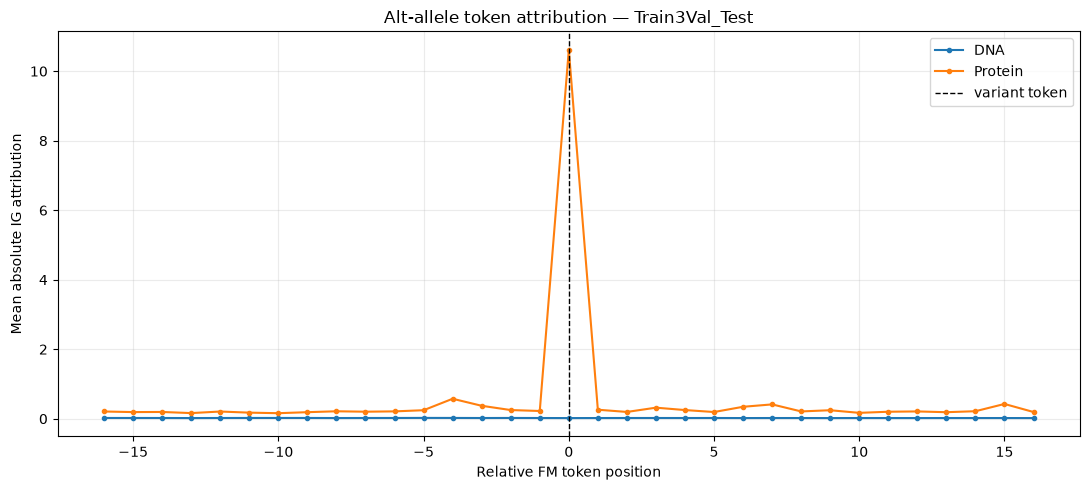

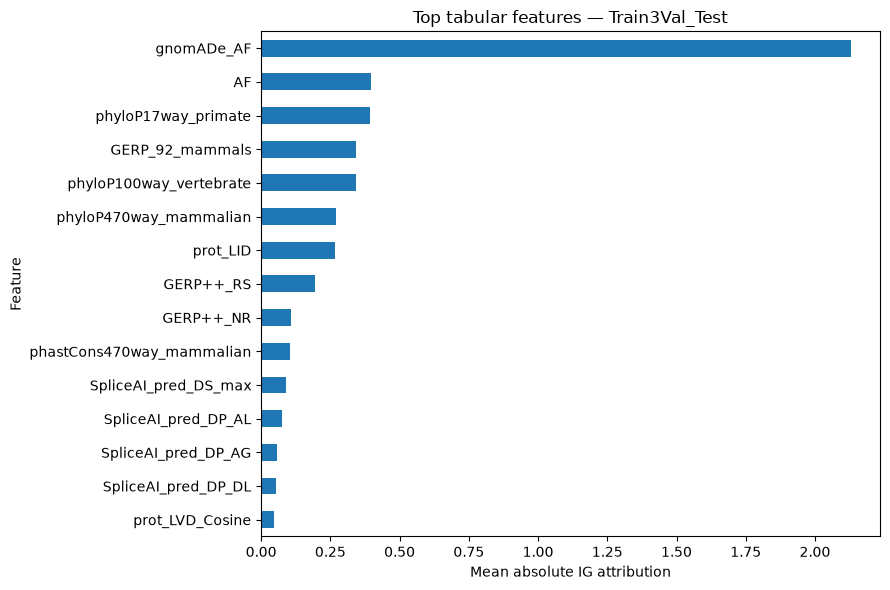

All explanation outputs are under: d:\Missense_variant_pathogenicity_prediction\experiments\cross_attention_explainability_v1


In [8]:
# Example plots for the standard test split; choose another dataset if needed.
PLOT_DATASET = "Train3Val_Test"
PLOT_MODE = "full_prediction"

if not IG_POSITIONS.empty:
    plot_frame = IG_POSITIONS[
        IG_POSITIONS["Dataset"].eq(PLOT_DATASET)
        & IG_POSITIONS["Attribution_Mode"].eq(PLOT_MODE)
        & IG_POSITIONS["Allele"].eq("Alt")
    ]
    if not plot_frame.empty:
        fig, ax = plt.subplots(figsize=(11, 5))
        for modality, frame in plot_frame.groupby("Modality"):
            curve = frame.groupby("Relative_Token_Position")["Absolute_Attribution"].mean()
            ax.plot(curve.index, curve.values, marker="o", markersize=3, label=modality)
        ax.axvline(0, color="black", linestyle="--", linewidth=1, label="variant token")
        ax.set(
            xlabel="Relative FM token position",
            ylabel="Mean absolute IG attribution",
            title=f"Alt-allele token attribution — {PLOT_DATASET}",
        )
        ax.legend()
        ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(OUTPUT_ROOT / "ig_alt_token_positions.png", dpi=160)
        plt.show()

if not IG_FEATURES.empty:
    feature_plot = IG_FEATURES[
        IG_FEATURES["Dataset"].eq(PLOT_DATASET)
        & IG_FEATURES["Attribution_Mode"].eq(PLOT_MODE)
    ].groupby("Feature")["Absolute_Attribution"].mean().nlargest(15).sort_values()
    if not feature_plot.empty:
        fig, ax = plt.subplots(figsize=(9, 6))
        feature_plot.plot.barh(ax=ax)
        ax.set(
            xlabel="Mean absolute IG attribution",
            title=f"Top tabular features — {PLOT_DATASET}",
        )
        fig.tight_layout()
        fig.savefig(OUTPUT_ROOT / "ig_top_features.png", dpi=160)
        plt.show()

print("All explanation outputs are under:", OUTPUT_ROOT)